In [1]:
print("Healthcare and Public Health Data Analysis")

print("My first Python project is ready!")

Healthcare and Public Health Data Analysis
My first Python project is ready!


In [2]:
!pip install pandas numpy matplotlib pytest

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pytest

print("All libraries imported successfully!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Pytest version:", pytest.__version__)

All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
Matplotlib version: 3.10.0
Pytest version: 8.4.2


In [7]:
import pandas as pd
import numpy as np
import os

# Set random seed for reproducibility
np.random.seed(42)

# Number of patients
n = 250

# Create healthcare dataset
data = {
    "Patient_ID": range(1, n + 1),

    "Age": np.random.randint(18, 86, n),

    "Gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "Disease": np.random.choice(
        ["Diabetes", "Hypertension", "Asthma",
         "Heart Disease", "Flu"], n
    ),

    "Blood_Pressure": np.random.randint(90, 181, n),

    "Glucose_Level": np.random.randint(70, 201, n),

    "BMI": np.round(
        np.random.uniform(16, 40, n), 2
    ),

    "Hospital_Visits": np.random.randint(1, 11, n),

    "Recovery_Status": np.random.choice(
        ["Recovered", "Under Treatment"], n
    )
}

# Convert dictionary into DataFrame
df = pd.DataFrame(data)

# Introduce missing values for preprocessing practice
df.loc[5, "Age"] = np.nan
df.loc[15, "BMI"] = np.nan
df.loc[25, "Glucose_Level"] = np.nan

# Introduce inconsistent data types
df["Age"] = df["Age"].astype(object)
df.loc[30, "Age"] = "45"

# Introduce one duplicate record
df = pd.concat(
    [df, df.iloc[[0]]],
    ignore_index=True
)

# Create project data directory
os.makedirs("data", exist_ok=True)

# Save dataset as CSV
df.to_csv("data/healthcare_data.csv", index=False)

print("Healthcare dataset created successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
print(df.head())
# Display dataset information
print("Dataset Information:")
print(df.info())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Display dataset dimensions
print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
from google.colab import files

files.download("data/healthcare_data.csv")
# Create a copy of the original dataset
clean_df = df.copy()

# Step 1: Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Step 2: Convert Age into numeric format
clean_df["Age"] = pd.to_numeric(
    clean_df["Age"], errors="coerce"
)

# Step 3: Handle missing values using median
clean_df["Age"] = clean_df["Age"].fillna(
    clean_df["Age"].median()
)

clean_df["Glucose_Level"] = clean_df["Glucose_Level"].fillna(
    clean_df["Glucose_Level"].median()
)

clean_df["BMI"] = clean_df["BMI"].fillna(
    clean_df["BMI"].median()
)

# Step 4: Save the cleaned dataset
os.makedirs("output", exist_ok=True)

clean_df.to_csv(
    "output/cleaned_healthcare_data.csv",
    index=False
)

# Display results
print("Data preprocessing completed successfully!")

print("\nCleaned Dataset:")
print(clean_df.head())

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(clean_df.duplicated().sum())

print("\nFinal Dataset Shape:", clean_df.shape)

print("\nCorrected Data Types:")
print(clean_df.dtypes)

Healthcare dataset created successfully!
Dataset shape: (251, 9)

First five records:
   Patient_ID   Age  Gender        Disease  Blood_Pressure  Glucose_Level  \
0           1  69.0  Female            Flu             166          147.0   
1           2  32.0    Male         Asthma              93          186.0   
2           3  78.0  Female         Asthma             151          189.0   
3           4  38.0    Male            Flu             154          145.0   
4           5  41.0  Female  Heart Disease             121          104.0   

     BMI  Hospital_Visits  Recovery_Status  
0  24.49                2  Under Treatment  
1  39.01                2  Under Treatment  
2  20.42                4        Recovered  
3  18.17                1        Recovered  
4  34.50                3        Recovered  
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  -----

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Data preprocessing completed successfully!

Cleaned Dataset:
   Patient_ID   Age  Gender        Disease  Blood_Pressure  Glucose_Level  \
0           1  69.0  Female            Flu             166          147.0   
1           2  32.0    Male         Asthma              93          186.0   
2           3  78.0  Female         Asthma             151          189.0   
3           4  38.0    Male            Flu             154          145.0   
4           5  41.0  Female  Heart Disease             121          104.0   

     BMI  Hospital_Visits  Recovery_Status  
0  24.49                2  Under Treatment  
1  39.01                2  Under Treatment  
2  20.42                4        Recovered  
3  18.17                1        Recovered  
4  34.50                3        Recovered  

Missing Values After Cleaning:
Patient_ID         0
Age                0
Gender             0
Disease            0
Blood_Pressure     0
Glucose_Level      0
BMI                0
Hospital_Visits    0
Recove

In [8]:
# STEP 1: Select numerical columns
numerical_columns = [
    "Age",
    "Blood_Pressure",
    "Glucose_Level",
    "BMI",
    "Hospital_Visits"
]

# STEP 2: Calculate statistical measures
print("HEALTHCARE DATA STATISTICAL ANALYSIS")
print("=" * 50)

for column in numerical_columns:

    print("\nAnalysis of:", column)
    print("-" * 40)

    mean_value = np.mean(clean_df[column])
    median_value = np.median(clean_df[column])
    std_value = np.std(clean_df[column], ddof=1)
    min_value = np.min(clean_df[column])
    max_value = np.max(clean_df[column])

    print("Mean:", round(mean_value, 2))
    print("Median:", round(median_value, 2))
    print("Standard Deviation:", round(std_value, 2))
    print("Minimum:", min_value)
    print("Maximum:", max_value)

HEALTHCARE DATA STATISTICAL ANALYSIS

Analysis of: Age
----------------------------------------
Mean: 50.73
Median: 50.0
Standard Deviation: 20.11
Minimum: 18.0
Maximum: 85.0

Analysis of: Blood_Pressure
----------------------------------------
Mean: 133.18
Median: 134.5
Standard Deviation: 26.91
Minimum: 90
Maximum: 180

Analysis of: Glucose_Level
----------------------------------------
Mean: 134.94
Median: 133.0
Standard Deviation: 37.6
Minimum: 70.0
Maximum: 200.0

Analysis of: BMI
----------------------------------------
Mean: 28.06
Median: 28.48
Standard Deviation: 7.41
Minimum: 16.01
Maximum: 39.98

Analysis of: Hospital_Visits
----------------------------------------
Mean: 5.4
Median: 5.0
Standard Deviation: 2.86
Minimum: 1
Maximum: 10


In [9]:
# Disease frequency
print("DISEASE FREQUENCY")
print(clean_df["Disease"].value_counts())

# Gender frequency
print("\nGENDER FREQUENCY")
print(clean_df["Gender"].value_counts())

# Recovery status frequency
print("\nRECOVERY STATUS FREQUENCY")
print(clean_df["Recovery_Status"].value_counts())

# Hospital visit frequency
print("\nHOSPITAL VISIT FREQUENCY")
print(clean_df["Hospital_Visits"].value_counts().sort_index())

DISEASE FREQUENCY
Disease
Flu              65
Diabetes         54
Heart Disease    45
Asthma           43
Hypertension     43
Name: count, dtype: int64

GENDER FREQUENCY
Gender
Female    138
Male      112
Name: count, dtype: int64

RECOVERY STATUS FREQUENCY
Recovery_Status
Recovered          130
Under Treatment    120
Name: count, dtype: int64

HOSPITAL VISIT FREQUENCY
Hospital_Visits
1     25
2     29
3     24
4     26
5     23
6     29
7     20
8     26
9     27
10    21
Name: count, dtype: int64


In [10]:
# Generate statistical summary
summary = clean_df[numerical_columns].describe()

print("STATISTICAL SUMMARY TABLE")
print(summary.round(2))

STATISTICAL SUMMARY TABLE
          Age  Blood_Pressure  Glucose_Level     BMI  Hospital_Visits
count  250.00          250.00         250.00  250.00           250.00
mean    50.73          133.18         134.94   28.06             5.40
std     20.11           26.91          37.60    7.41             2.86
min     18.00           90.00          70.00   16.01             1.00
25%     34.00          110.00         104.00   21.58             3.00
50%     50.00          134.50         133.00   28.48             5.00
75%     69.00          155.00         168.75   34.50             8.00
max     85.00          180.00         200.00   39.98            10.00


In [11]:
# Save statistical summary as CSV
summary.to_csv("output/statistical_summary.csv")

print("Statistical summary saved successfully!")

Statistical summary saved successfully!


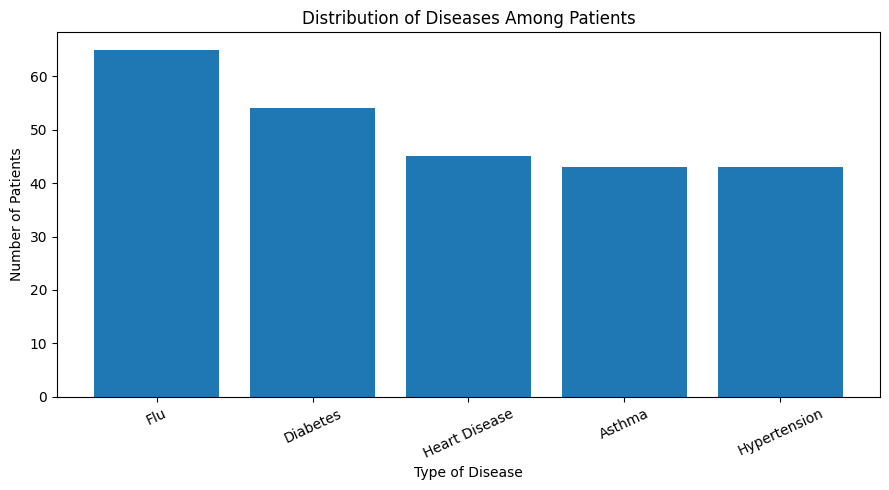

In [12]:
# Disease Distribution Bar Chart

disease_count = clean_df["Disease"].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(
    disease_count.index,
    disease_count.values
)

plt.title("Distribution of Diseases Among Patients")
plt.xlabel("Type of Disease")
plt.ylabel("Number of Patients")

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig("output/disease_distribution.png")

plt.show()

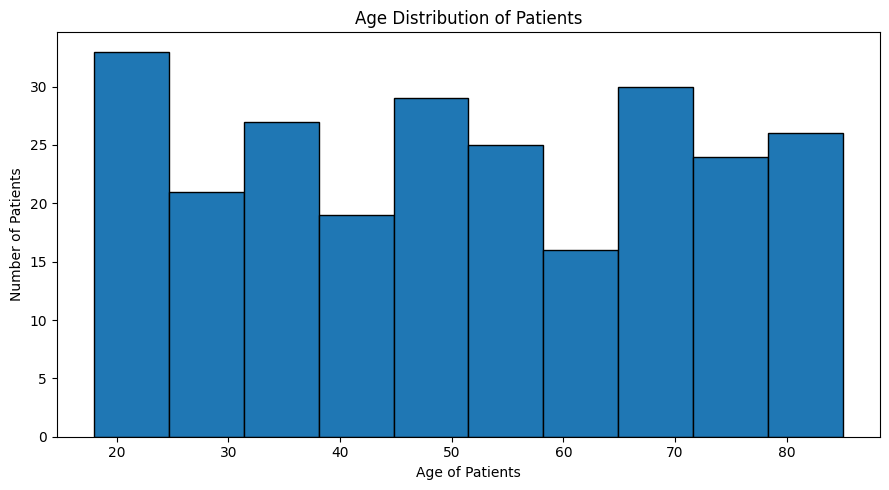

In [13]:
# Patient Age Distribution Histogram

plt.figure(figsize=(9, 5))

plt.hist(
    clean_df["Age"],
    bins=10,
    edgecolor="black"
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age of Patients")
plt.ylabel("Number of Patients")

plt.tight_layout()

plt.savefig("output/age_distribution.png")

plt.show()

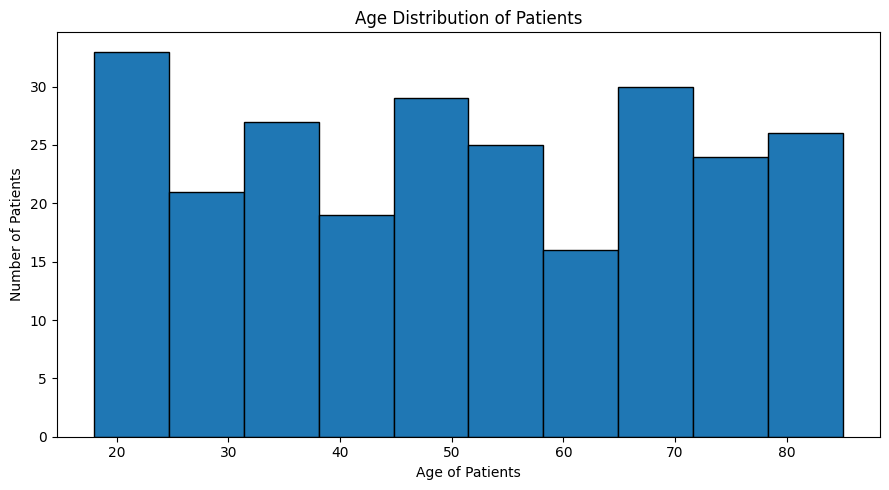

In [14]:
# Patient Age Distribution Histogram

plt.figure(figsize=(9, 5))

plt.hist(
    clean_df["Age"],
    bins=10,
    edgecolor="black"
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age of Patients")
plt.ylabel("Number of Patients")

plt.tight_layout()

plt.savefig("output/age_distribution.png")

plt.show()

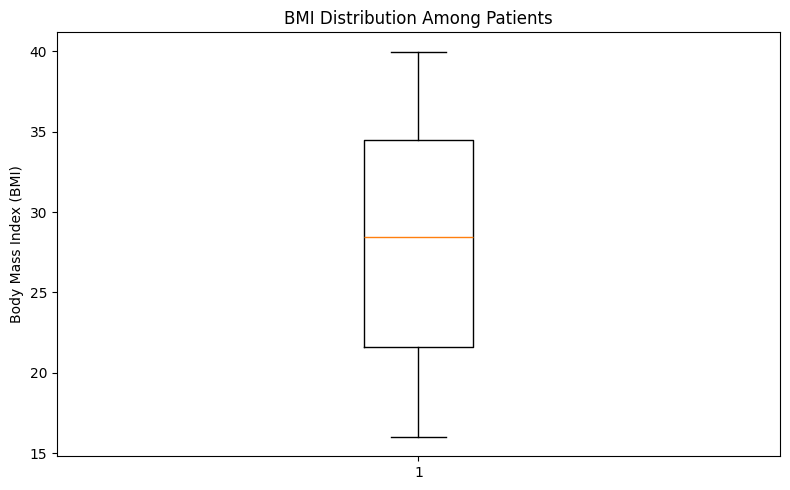

In [15]:
# BMI Distribution Box Plot

plt.figure(figsize=(8, 5))

plt.boxplot(
    clean_df["BMI"],
    vert=True
)

plt.title("BMI Distribution Among Patients")
plt.ylabel("Body Mass Index (BMI)")

plt.tight_layout()

plt.savefig("output/bmi_distribution.png")

plt.show()

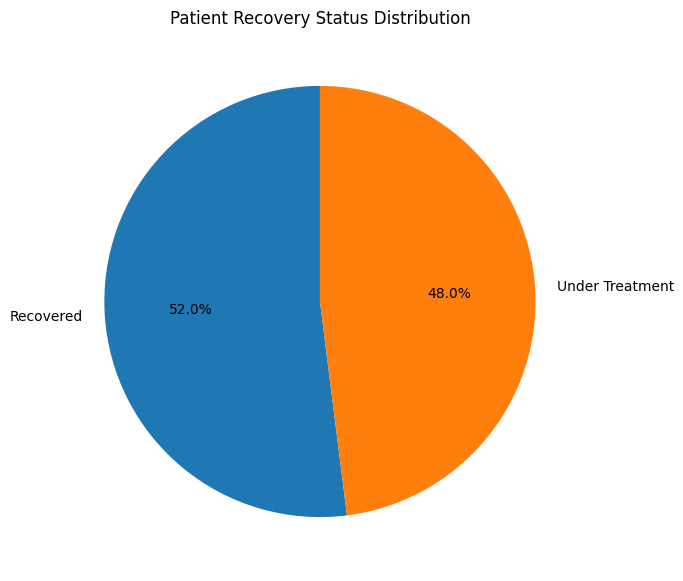

In [16]:
# Recovery Status Pie Chart

recovery_count = clean_df["Recovery_Status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    recovery_count.values,
    labels=recovery_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Patient Recovery Status Distribution")

plt.savefig("output/recovery_status.png")

plt.show()

In [17]:
# Display generated output files

print("PROJECT OUTPUT FILES")
print("=" * 40)

for file in os.listdir("output"):
    print(file)

print("\nAll visualizations saved successfully!")

PROJECT OUTPUT FILES
cleaned_healthcare_data.csv
age_distribution.png
statistical_summary.csv
recovery_status.png
bmi_distribution.png
disease_distribution.png

All visualizations saved successfully!


In [18]:
import os

# Create project folders
os.makedirs("src", exist_ok=True)
os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [19]:
%%writefile src/data_loader.py

import pandas as pd


def load_data(file_path):
    """
    Load healthcare data from a CSV file.

    Parameters:
        file_path (str): Location of the CSV file.

    Returns:
        DataFrame: Loaded healthcare dataset.
    """
    try:
        data = pd.read_csv(file_path)
        print("Dataset loaded successfully!")
        return data

    except FileNotFoundError:
        raise FileNotFoundError("Dataset file not found.")

    except Exception as error:
        raise ValueError(f"Error loading dataset: {error}")

Writing src/data_loader.py


In [20]:
%%writefile src/preprocessing.py

import pandas as pd


def clean_data(data):
    """
    Clean the healthcare dataset.

    Parameters:
        data (DataFrame): Original healthcare dataset.

    Returns:
        DataFrame: Cleaned healthcare dataset.
    """

    data = data.copy()

    # Remove duplicate records
    data = data.drop_duplicates()

    # Convert Age into numeric format
    data["Age"] = pd.to_numeric(
        data["Age"], errors="coerce"
    )

    # Fill missing numerical values with median
    numerical_columns = [
        "Age",
        "Glucose_Level",
        "BMI"
    ]

    for column in numerical_columns:
        data[column] = data[column].fillna(
            data[column].median()
        )

    return data

Writing src/preprocessing.py


In [21]:
from src.data_loader import load_data
from src.preprocessing import clean_data

# Load original dataset
raw_data = load_data("data/healthcare_data.csv")

# Clean dataset
processed_data = clean_data(raw_data)

print("Modular programming test successful!")
print("Original shape:", raw_data.shape)
print("Cleaned shape:", processed_data.shape)

Dataset loaded successfully!
Modular programming test successful!
Original shape: (251, 9)
Cleaned shape: (250, 9)


In [22]:
%%writefile src/analysis.py

import pandas as pd
import numpy as np


def perform_analysis(data, output_dir="output"):
    """
    Perform statistical analysis on healthcare data.

    Parameters:
        data (DataFrame): Cleaned healthcare dataset.
        output_dir (str): Directory to save analysis results.

    Returns:
        DataFrame: Statistical summary.
    """

    import os
    os.makedirs(output_dir, exist_ok=True)

    numerical_columns = [
        "Age",
        "Blood_Pressure",
        "Glucose_Level",
        "BMI",
        "Hospital_Visits"
    ]

    # Calculate statistical summary
    summary = data[numerical_columns].describe()

    # Save statistical summary
    summary.to_csv(
        os.path.join(output_dir, "statistical_summary.csv")
    )

    # Calculate frequency distributions
    for column in ["Disease", "Gender", "Recovery_Status"]:
        frequency = data[column].value_counts()

        frequency.to_csv(
            os.path.join(output_dir, f"{column.lower()}_frequency.csv")
        )

    print("Statistical analysis completed!")

    return summary

Writing src/analysis.py


In [23]:
%%writefile src/visualization.py

import matplotlib.pyplot as plt
import os


def generate_visualizations(data, output_dir="output"):
    """
    Generate healthcare data visualizations.

    Parameters:
        data (DataFrame): Cleaned healthcare dataset.
        output_dir (str): Directory to save charts.

    Returns:
        None
    """

    os.makedirs(output_dir, exist_ok=True)

    # 1. Disease Distribution
    disease_count = data["Disease"].value_counts()

    plt.figure(figsize=(9, 5))
    plt.bar(disease_count.index, disease_count.values)
    plt.title("Distribution of Diseases Among Patients")
    plt.xlabel("Type of Disease")
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "disease_distribution.png"))
    plt.close()

    # 2. Age Distribution
    plt.figure(figsize=(9, 5))
    plt.hist(data["Age"], bins=10, edgecolor="black")
    plt.title("Age Distribution of Patients")
    plt.xlabel("Age of Patients")
    plt.ylabel("Number of Patients")
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "age_distribution.png"))
    plt.close()

    # 3. BMI Distribution
    plt.figure(figsize=(8, 5))
    plt.boxplot(data["BMI"])
    plt.title("BMI Distribution Among Patients")
    plt.ylabel("Body Mass Index")
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "bmi_distribution.png"))
    plt.close()

    # 4. Recovery Status
    recovery_count = data["Recovery_Status"].value_counts()

    plt.figure(figsize=(7, 7))
    plt.pie(
        recovery_count.values,
        labels=recovery_count.index,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Patient Recovery Status Distribution")
    plt.savefig(os.path.join(output_dir, "recovery_status.png"))
    plt.close()

    print("All four visualizations generated successfully!")

Writing src/visualization.py


In [24]:
from src.analysis import perform_analysis
from src.visualization import generate_visualizations

# Perform statistical analysis
summary = perform_analysis(processed_data)

# Generate four visualizations
generate_visualizations(processed_data)

# Display statistical summary
print("\nSTATISTICAL SUMMARY:")
print(summary.round(2))

print("\nModules executed successfully!")

Statistical analysis completed!
All four visualizations generated successfully!

STATISTICAL SUMMARY:
          Age  Blood_Pressure  Glucose_Level     BMI  Hospital_Visits
count  250.00          250.00         250.00  250.00           250.00
mean    50.73          133.18         134.94   28.06             5.40
std     20.11           26.91          37.60    7.41             2.86
min     18.00           90.00          70.00   16.01             1.00
25%     34.00          110.00         104.00   21.58             3.00
50%     50.00          134.50         133.00   28.48             5.00
75%     69.00          155.00         168.75   34.50             8.00
max     85.00          180.00         200.00   39.98            10.00

Modules executed successfully!


In [25]:
print("PROJECT MODULES")
print("=" * 35)

for file in os.listdir("src"):
    print(file)

print("\nOUTPUT FILES")
print("=" * 35)

for file in os.listdir("output"):
    print(file)

PROJECT MODULES
preprocessing.py
data_loader.py
__pycache__
visualization.py
analysis.py

OUTPUT FILES
cleaned_healthcare_data.csv
age_distribution.png
gender_frequency.csv
statistical_summary.csv
disease_frequency.csv
recovery_status.png
recovery_status_frequency.csv
bmi_distribution.png
disease_distribution.png


In [26]:
%%writefile src/main.py

import os

from data_loader import load_data
from preprocessing import clean_data
from analysis import perform_analysis
from visualization import generate_visualizations


def main():
    """
    Execute the complete healthcare data analysis application.
    """

    input_file = "data/healthcare_data.csv"
    output_dir = "output"

    os.makedirs(output_dir, exist_ok=True)

    # Load dataset
    data = load_data(input_file)

    # Clean dataset
    cleaned_data = clean_data(data)

    # Save cleaned dataset
    cleaned_data.to_csv(
        os.path.join(output_dir, "cleaned_healthcare_data.csv"),
        index=False
    )

    # Perform statistical analysis
    perform_analysis(cleaned_data, output_dir)

    # Generate visualizations
    generate_visualizations(cleaned_data, output_dir)

    print("\nHealthcare Data Analysis Completed!")
    print("Cleaned records:", len(cleaned_data))
    print("Output directory:", output_dir)


if __name__ == "__main__":
    main()

Writing src/main.py


In [27]:
import sys

sys.path.insert(0, os.path.abspath("src"))

from main import main

main()

Dataset loaded successfully!
Statistical analysis completed!
All four visualizations generated successfully!

Healthcare Data Analysis Completed!
Cleaned records: 250
Output directory: output


In [28]:
import os

os.makedirs("tests", exist_ok=True)

print("Tests folder created successfully!")

Tests folder created successfully!


In [29]:
%%writefile tests/test_analysis.py

import pandas as pd
import pytest

from src.preprocessing import clean_data
from src.analysis import perform_analysis
from src.data_loader import load_data


def test_valid_dataset_loading():
    """Test whether a valid CSV file loads successfully."""

    data = load_data("data/healthcare_data.csv")

    assert isinstance(data, pd.DataFrame)
    assert len(data) == 251


def test_missing_values_handling():
    """Test whether missing values are handled."""

    data = pd.DataFrame({
        "Age": [20, None, 40],
        "Glucose_Level": [100, 120, None],
        "BMI": [22, None, 30]
    })

    # Add other required columns
    data["Patient_ID"] = [1, 2, 3]

    cleaned = clean_data(data)

    assert cleaned.isnull().sum().sum() == 0


def test_duplicate_removal():
    """Test whether duplicate records are removed."""

    data = pd.DataFrame({
        "Patient_ID": [1, 1],
        "Age": [25, 25],
        "Glucose_Level": [100, 100],
        "BMI": [22, 22]
    })

    cleaned = clean_data(data)

    assert cleaned.duplicated().sum() == 0
    assert len(cleaned) == 1


def test_invalid_file():
    """Test handling of a missing CSV file."""

    with pytest.raises(FileNotFoundError):
        load_data("data/invalid_file.csv")


def test_statistical_analysis():
    """Test whether statistical analysis works."""

    data = pd.DataFrame({
        "Age": [20, 30, 40],
        "Blood_Pressure": [100, 110, 120],
        "Glucose_Level": [90, 100, 110],
        "BMI": [20, 25, 30],
        "Hospital_Visits": [1, 2, 3]
    })

    summary = perform_analysis(data, "output/test_results")

    assert summary.loc["mean", "Age"] == 30

Writing tests/test_analysis.py


In [36]:
%%writefile tests/test_analysis.py

import pandas as pd
import pytest

from src.data_loader import load_data
from src.preprocessing import clean_data
from src.analysis import perform_analysis


def test_valid_dataset_loading():
    data = load_data("data/healthcare_data.csv")
    assert isinstance(data, pd.DataFrame)
    assert len(data) == 251


def test_missing_values_handling():
    data = pd.DataFrame({
        "Age": [20, None, 40],
        "Glucose_Level": [90, 100, None],
        "BMI": [22, None, 28]
    })

    cleaned = clean_data(data)
    assert cleaned.isnull().sum().sum() == 0


def test_duplicate_removal():
    data = pd.DataFrame({
        "Age": [20, 20],
        "Glucose_Level": [90, 90],
        "BMI": [22, 22]
    })

    cleaned = clean_data(data)
    assert len(cleaned) == 1


def test_invalid_file():
    with pytest.raises(FileNotFoundError):
        load_data("invalid_file.csv")


def test_statistical_analysis():
    data = pd.DataFrame({
        "Age": [20, 30, 40],
        "Blood_Pressure": [100, 110, 120],
        "Glucose_Level": [90, 100, 110],
        "BMI": [20, 25, 30],
        "Hospital_Visits": [1, 2, 3],
        "Disease": ["Flu", "Diabetes", "Asthma"],
        "Gender": ["Male", "Female", "Male"],
        "Recovery_Status": [
            "Recovered",
            "Under Treatment",
            "Recovered"
        ]
    })

    summary = perform_analysis(data, "output/test_results")
    assert summary.loc["mean", "Age"] == 30

Overwriting tests/test_analysis.py


In [37]:
!python -m pytest tests/test_analysis.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.14.3, typeguard-4.6.0, anyio-4.16.0, langsmith-0.14.17
collected 5 items                                                              

tests/test_analysis.py::test_valid_dataset_loading PASSED                [ 20%]
tests/test_analysis.py::test_missing_values_handling PASSED              [ 40%]
tests/test_analysis.py::test_duplicate_removal PASSED                    [ 60%]
tests/test_analysis.py::test_invalid_file PASSED                         [ 80%]
tests/test_analysis.py::test_statistical_analysis PASSED                 [100%]

============================== 5 passed in 0.58s ===============================


In [38]:
!python -m pytest tests/test_analysis.py -v | tee test_results.txt

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.14.3, typeguard-4.6.0, anyio-4.16.0, langsmith-0.14.17
collecting ... collected 5 items

tests/test_analysis.py::test_valid_dataset_loading PASSED                [ 20%]
tests/test_analysis.py::test_missing_values_handling PASSED              [ 40%]
tests/test_analysis.py::test_duplicate_removal PASSED                    [ 60%]
tests/test_analysis.py::test_invalid_file PASSED                         [ 80%]
tests/test_analysis.py::test_statistical_analysis PASSED                 [100%]

============================== 5 passed in 0.82s ===============================


In [39]:
%%writefile requirements.txt
pandas
numpy
matplotlib
pytest

Writing requirements.txt


In [40]:
import os
import shutil

project = "Healthcare-Public-Health-Analysis"

os.makedirs(project, exist_ok=True)

folders = [
    "data",
    "src",
    "output",
    "tests",
    "notebooks"
]

for folder in folders:
    os.makedirs(f"{project}/{folder}", exist_ok=True)

# Copy project files and folders
for folder in ["data", "src", "output", "tests"]:
    if os.path.exists(folder):
        shutil.copytree(folder, f"{project}/{folder}", dirs_exist_ok=True)

# Copy documentation and dependency files
for file in ["requirements.txt", "test_results.txt"]:
    if os.path.exists(file):
        shutil.copy(file, project)

print("Project folders organised successfully!")

Project folders organised successfully!


In [41]:
%%writefile Healthcare-Public-Health-Analysis/README.md

# Healthcare and Public Health Data Analysis

## 1. Project Overview

This project is a Python-based data science application developed to analyse healthcare and public health data.

It uses a simulated healthcare dataset containing 250 patient records. The application performs data cleaning, statistical analysis and data visualisation to identify patterns in the dataset.

## 2. Objectives

- To load and analyse healthcare data using Python.
- To identify and handle missing and duplicate values.
- To calculate statistical measures such as mean, median and standard deviation.
- To create visualisations using Matplotlib.
- To develop a modular and reproducible data science application.

## 3. Dataset Description

The dataset contains the following attributes:

- Patient_ID
- Age
- Gender
- Disease
- Blood_Pressure
- Glucose_Level
- BMI
- Hospital_Visits
- Recovery_Status

Note: This project uses simulated data for educational purposes. It does not contain real patient information.

## 4. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Pytest
- Google Colab

## 5. Project Structure

```text
Healthcare-Public-Health-Analysis/
|
|-- data/
|-- src/
|-- output/
|-- tests/
|-- notebooks/
|-- requirements.txt
|-- test_results.txt
|-- README.md

Writing Healthcare-Public-Health-Analysis/README.md


In [42]:
pip install -r requirements.txt

In [44]:
!python Healthcare-Public-Health-Analysis/src/main.py

Dataset loaded successfully!
Statistical analysis completed!
All four visualizations generated successfully!

Healthcare Data Analysis Completed!
Cleaned records: 250
Output directory: output


In [45]:
import os

for root, dirs, files in os.walk("Healthcare-Public-Health-Analysis"):
    print(root, ":", files)

Healthcare-Public-Health-Analysis : ['requirements.txt', 'README.md', 'test_results.txt']
Healthcare-Public-Health-Analysis/tests : ['test_analysis.py']
Healthcare-Public-Health-Analysis/tests/__pycache__ : ['test_analysis.cpython-313-pytest-8.4.2.pyc']
Healthcare-Public-Health-Analysis/notebooks : []
Healthcare-Public-Health-Analysis/data : ['healthcare_data.csv']
Healthcare-Public-Health-Analysis/output : ['cleaned_healthcare_data.csv', 'age_distribution.png', 'gender_frequency.csv', 'statistical_summary.csv', 'disease_frequency.csv', 'recovery_status.png', 'recovery_status_frequency.csv', 'bmi_distribution.png', 'disease_distribution.png']
Healthcare-Public-Health-Analysis/output/test_results : ['gender_frequency.csv', 'statistical_summary.csv', 'disease_frequency.csv', 'recovery_status_frequency.csv']
Healthcare-Public-Health-Analysis/src : ['preprocessing.py', 'data_loader.py', 'visualization.py', 'main.py', 'analysis.py']
Healthcare-Public-Health-Analysis/src/__pycache__ : ['data

In [46]:
import os
import shutil

project = "Healthcare-Public-Health-Analysis"

# Synchronise the latest files
for folder in ["src", "data", "output", "tests"]:
    shutil.copytree(
        folder,
        f"{project}/{folder}",
        dirs_exist_ok=True
    )

# Create package initialisation file
open(f"{project}/src/__init__.py", "w").close()

# Remove unnecessary cache folders
for root, dirs, files in os.walk(project, topdown=False):
    for folder in dirs:
        if folder == "__pycache__":
            shutil.rmtree(os.path.join(root, folder))

print("Final project files updated successfully!")

Final project files updated successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()